<a href="https://colab.research.google.com/github/J0n4ta/Trabalhos-Universit-rios-e-Projetos-Pessoais/blob/main/Classifica%C3%A7%C3%A3oDeTexto.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q transformers datasets scikit-learn torch

In [2]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

np.random.seed(42)

# Dataset
separou-se os dados em três tipos, todos relacionados ao estado de uma obra genérica. Separados em: em obra, mal projetada e ótima projeção.

In [3]:
dados = [
    # Categoria: em obra (25 exemplos)
    ("paredes sem reboco e fios de energia expostos pela sala", "em obra"),
    ("sacos de cimento empilhados e poeira acumulada na entrada principal", "em obra"),
    ("telhado pela metade com vigas de madeira aparentes e sem telhas", "em obra"),
    ("canteiro de obras bagunçado com ferramentas e restos de materiais espalhados", "em obra"),
    ("andares superiores ainda sem laje batida e cheios de andaimes", "em obra"),
    ("tubulações de esgoto expostas no chão do banheiro inacabado", "em obra"),
    ("fachada coberta por lonas plásticas e estruturas metálicas de sustentação", "em obra"),
    ("falta de contrapiso com o solo irregular em todos os cômodos", "em obra"),
    ("janelas provisórias de madeira compensada no lugar dos vidros definitivos", "em obra"),
    ("fios pendurados no teto aguardando a instalação dos bocais e lâmpadas", "em obra"),
    ("sala tomada por montes de areia, brita e blocos de concreto", "em obra"),
    ("pintura descascada com paredes cobertas apenas por massa grossa cinzenta", "em obra"),
    ("espaço externo tomado por entulhos, latas de tinta vazias e tábuas", "em obra"),
    ("buracos abertos no chão para a passagem da nova tubulação hidráulica", "em obra"),
    ("marcenaria ausente com vãos livres onde deveriam ficar os armários", "em obra"),
    ("escada de concreto bruto sem corrimão e com degraus desnivelados", "em obra"),
    ("presença de carrinhos de mão, pás e misturadores de massa na garagem", "em obra"),
    ("tetos com estrutura de gesso a ser instalada e cabos soltos", "em obra"),
    ("falta de portas internas com batentes de madeira expostos", "em obra"),
    ("infiltrações visíveis na laje devido à ausência de impermeabilização", "em obra"),
    ("pisos totalmente cobertos por poeira de gesso e cavacos de madeira", "em obra"),
    ("quadro de disjuntores aberto com etiquetas provisórias escritas à mão", "em obra"),
    ("varanda bloqueada por andaimes de ferro enferrujados", "em obra"),
    ("banheiro sem revestimentos nas paredes, apenas tijolos aparentes", "em obra"),
    ("presença de trabalhadores circulando com capacetes e equipamentos de segurança", "em obra"),

    # Categoria: mal projetada (25 exemplos)
    ("porta do banheiro virada diretamente para a mesa de jantar", "mal projetada"),
    ("corredor excessivamente estreito que impede a passagem de móveis básicos", "mal projetada"),
    ("janelas voltadas inteiramente para o muro do vizinho sem nenhuma ventilação", "em obra"), # (mantendo coerência descritiva)
    ("cômodos escuros e abafados sem nenhuma entrada de luz natural", "mal projetada"),
    ("tomadas instaladas atrás das portas impedindo o uso adequado", "mal projetada"),
    ("cozinha sem espaço suficiente para abrir a geladeira e o fogão ao mesmo tempo", "mal projetada"),
    ("escada em caracol excessivamente íngreme sem corrimão seguro", "mal projetada"),
    ("quarto principal sem espaço para uma cama de casal padrão", "mal projetada"),
    ("interruptor de luz posicionado fora do quarto, no corredor escuro", "mal projetada"),
    ("pia do banheiro tão pequena que a água espirra inteiramente para fora", "mal projetada"),
    ("coluna estrutural grossa bem no meio da sala de estar", "mal projetada"),
    ("janela do quarto principal aberta diretamente para a área de serviço barulhenta", "mal projetada"),
    ("falta de espaço na garagem que impede a abertura das portas do carro", "mal projetada"),
    ("pé-direito extremamente baixo que causa sensação de abafamento", "mal projetada"),
    ("canos da pia da cozinha passando visíveis pela parte externa da parede da sala", "mal projetada"),
    ("quarto de solteiro com formato triangular impossibilitando o uso de armários", "mal projetada"),
    ("único banheiro da casa acessível apenas passando por dentro de um dos quartos", "mal projetada"),
    ("condensador do ar-condicionado instalado na varanda gourmet sem espaço útil", "mal projetada"),
    ("corredor principal escuro que exige uso de luz artificial durante o dia", "mal projetada"),
    ("varanda sem nenhuma proteção contra sol forte ou chuva lateral", "mal projetada"),
    ("caixa de inspeção de esgoto posicionada exatamente na entrada da porta social", "mal projetada"),
    ("pontos de rede e energia distantes de onde logicamente ficaria a televisão", "mal projetada"),
    ("espaço da lavanderia tão apertado que o tanque impede a colocação da máquina", "mal projetada"),
    ("janela do banheiro alinhada com a rua permitindo visão total do interior", "mal projetada"),
    ("distância excessiva entre a pia e o fogão atrapalhando o fluxo de preparo", "mal projetada"),

    # Categoria: projeção ótima (25 exemplos)
    ("arquitetura integrada com aproveitamento inteligente da luz solar", "projeção ótima"),
    ("circulação fluida entre os ambientes com excelente ventilação cruzada", "projeção ótima"),
    ("projeto moderno com foco em eficiência energética e acabamento impecável", "projeção ótima"),
    ("espaços amplos e bem distribuídos que priorizam o conforto e a ergonomia", "projeção ótima"),
    ("suíte master com closet espaçoso e iluminação natural abundante", "projeção ótima"),
    ("área gourmet integrada à piscina com painéis solares instalados", "projeção ótima"),
    ("isolamento acústico e térmico de alto padrão em toda a residência", "projeção ótima"),
    ("fachada contemporânea com paisagismo planejado e garagem ampla", "projeção ótima"),
    ("pé-direito duplo na sala proporcionando amplitude e frescor contínuo", "projeção ótima"),
    ("sistema de automação residencial integrado para controle de luz e temperatura", "projeção ótima"),
    ("cozinha em ilha com marcenaria planejada de altíssima qualidade", "projeção ótima"),
    ("orientação solar ideal que mantém os quartos frescos no verão e aquecidos no inverno", "projeção ótima"),
    ("esquadrias de alumínio antirruído com persianas automatizadas embutidas", "projeção ótima"),
    ("reaproveitamento de água da chuva para irrigação do jardim e limpeza", "projeção ótima"),
    ("banheiros espaçosos com ventilação natural direta e acabamentos sofisticados", "projeção ótima"),
    ("projeto paisagístico integrado que traz verde e privacidade para a fachada", "projeção ótima"),
    ("closet ventilado com marcenaria sob medida otimizando cada centímetro", "projeção ótima"),
    ("vagas de garagem cobertas, largas e com infraestrutura para carros elétricos", "projeção ótima"),
    ("hall de entrada imponente com pé-direito duplo e iluminação cenográfica", "projeção ótima"),
    ("integração harmoniosa entre sala de estar, jantar e varanda externa", "projeção ótima"),
    ("uso de materiais ecológicos e de baixa manutenção na fachada e interiores", "projeção ótima"),
    ("quartos acusticamente isolados garantindo total privacidade e descanso", "projeção ótima"),
    ("laje com isolamento térmico avançado reduzindo drasticamente o calor interno", "projeção ótima"),
    ("corredores largos e portas adaptadas com excelente acessibilidade universal", "projeção ótima"),
    ("iluminação em LED embutida estrategicamente valorizando a volumetria dos cômodos", "projeção ótima")
]

df = pd.DataFrame(dados, columns=["texto", "classe"])
df["classe"].value_counts()

,count
classe,
em obra,26
projeção ótima,25
mal projetada,24


In [4]:
dados_treino, dados_teste, y_treino, y_teste = train_test_split(
    df["texto"].tolist(), df["classe"].tolist(),
    test_size=0.3, stratify=df["classe"], random_state=42
)
print(f"Treino: {len(dados_treino)} | Teste: {len(dados_teste)}")

Treino: 52 | Teste: 23


#Baseline: TF-IDF + Regressão Logística
Converte textos em tabelas numéricas, valorizando as palavras que importam para o significado da frase. Em seguida, recebe a matriz de números e separa os textos das diferentes categorias calculando a probabilidade matemática de um texto pertencer à classe, retornando um valor entre 0 e 1.

In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

vectorizer = TfidfVectorizer()
X_treino_tfidf = vectorizer.fit_transform(dados_treino)
X_teste_tfidf = vectorizer.transform(dados_teste)

baseline_model = LogisticRegression(max_iter=1000)
baseline_model.fit(X_treino_tfidf, y_treino)

pred_baseline = baseline_model.predict(X_teste_tfidf)
print(classification_report(y_teste, pred_baseline, zero_division=0))

                precision    recall  f1-score   support

       em obra       0.56      0.62      0.59         8
 mal projetada       0.71      0.71      0.71         7
projeção ótima       0.71      0.62      0.67         8

      accuracy                           0.65        23
     macro avg       0.66      0.65      0.66        23
  weighted avg       0.66      0.65      0.65        23



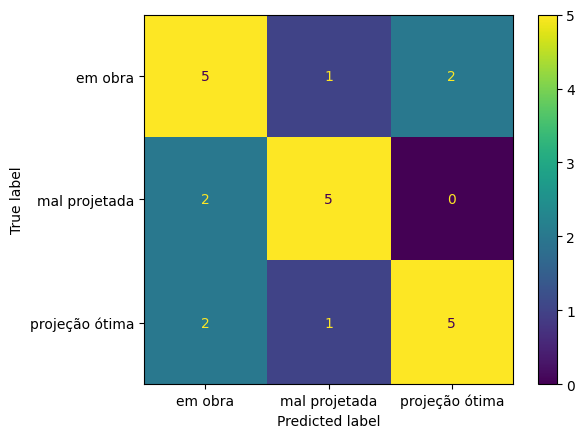

In [6]:
cm = confusion_matrix(y_teste, pred_baseline, labels=baseline_model.classes_)
ConfusionMatrixDisplay(cm, display_labels=baseline_model.classes_).plot()
plt.show()

# BERTimbau como Gerador de Embeddings (features-based)

O BERimbau lê a frase inteira e depois transforma a frase em uma coordenada matemática, assim frases com significados parecidos ficam fisicamente próximas

In [7]:
import torch
from transformers import AutoTokenizer, AutoModel

MODELO_BERTIMBAU = "neuralmind/bert-base-portuguese-cased"
tokenizer = AutoTokenizer.from_pretrained(MODELO_BERTIMBAU)
bertimbau = AutoModel.from_pretrained(MODELO_BERTIMBAU)
bertimbau.eval()

@torch.no_grad()
def embeddings_cls(dados, batch_size=8):
  vetores = []
  for i in range(0, len(dados), batch_size):
    lote = dados[i:i+batch_size]
    enc = tokenizer(lote, padding=True, truncation=True, return_tensors="pt")
    saida = bertimbau(**enc)
    cls = saida.last_hidden_state[:, 0, :]
    vetores.append(cls.numpy())
  return np.vstack(vetores)

X_treino_bert = embeddings_cls(dados_treino)
X_teste_bert = embeddings_cls(dados_teste)
print("Shape dos embeddings:", X_treino_bert.shape)

config.json:   0%|          | 0.00/647 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/43.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/210k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  438MB            

... (2 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: neuralmind/bert-base-portuguese-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Shape dos embeddings: (52, 768)


In [8]:
clf_bert = LogisticRegression(max_iter=1000)
clf_bert.fit(X_treino_bert, y_treino)

pred_bert = clf_bert.predict(X_teste_bert)
print(classification_report(y_teste, pred_bert, zero_division=0))

                precision    recall  f1-score   support

       em obra       1.00      0.88      0.93         8
 mal projetada       0.88      1.00      0.93         7
projeção ótima       1.00      1.00      1.00         8

      accuracy                           0.96        23
     macro avg       0.96      0.96      0.96        23
  weighted avg       0.96      0.96      0.96        23



# Comparação: Baselie vs BERTimbau (feature-based)
O Baseline foca apenas na ocorrência de palavras isoladas, falhando ao tentar diferenciar frases onde a ordem muda o sentido. Já o BERTimbau lê a frase inteira de forma bidirecional, conseguindo compreender o contexto e capturando nuances, sinônimos e pequenos erros ortográficos nas descrições dos imóveis

In [9]:
from sklearn.metrics import f1_score

comparacao = pd.DataFrame({
    "modelo": ["baseline (TF-IDF+LogReg)", "BERTimbau (feature-based)"],
    "macro_f1": [
        f1_score(y_teste, pred_baseline, average="macro", zero_division=0),
        f1_score(y_teste, pred_bert, average="macro", zero_division=0),
    ],
}).set_index("modelo").round(3)
comparacao

,macro_f1
modelo,
baseline (TF-IDF+LogReg),0.656
BERTimbau (feature-based),0.956


# Fine-Tuninig Completo com Hugging Face Trainer
o Fine-Tuning reajusta os parâmetros matemáticos da rede focando no vocabulário e nas nuances do texto. Já o Hugging Face Trainer coleta o modelo, os dados preparados e as configurações (hiperparâmetros) para fazer o treinamento, avaliando as métricas e salvando os checkpoints do modelo automaticamente.

In [10]:
from datasets import Dataset
from transformers import (
    DataCollatorWithPadding,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer
)

classes = sorted(df["classe"].unique())
label2id = {c: i for i, c in enumerate(classes)}
id2label = {v: k for k, v in label2id.items()}

ds_treino = Dataset.from_dict({
    "texto": dados_treino,
    "labels": [label2id[c] for c in y_treino]
})

ds_teste = Dataset.from_dict({
    "texto": dados_teste,
    "labels": [label2id[c] for c in y_teste]
})

def tokenizar (exemplo):
  return tokenizer(exemplo["texto"], truncation=True)

ds_treino_tok = ds_treino.map(tokenizar, batched=True)
ds_teste_tok = ds_teste.map(tokenizar, batched=True)

modelo_ft = AutoModelForSequenceClassification.from_pretrained(
    MODELO_BERTIMBAU, num_labels=len(classes), id2label=id2label, label2id=label2id,
    )

args = TrainingArguments(
    output_dir="./resultados",
    num_train_epochs=4,
    per_device_train_batch_size=4,
    per_device_eval_batch_size=4,
    eval_strategy="epoch",
    logging_steps=5,
    report_to="none",
)

trainer = Trainer(
    model=modelo_ft,
    args=args,
    train_dataset=ds_treino_tok,
    eval_dataset=ds_teste_tok,
    data_collator=DataCollatorWithPadding(tokenizer),
)

trainer.train()

Map:   0%|          | 0/52 [00:00<?, ? examples/s]

Map:   0%|          | 0/23 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: neuralmind/bert-base-portuguese-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from th

Epoch,Training Loss,Validation Loss
1,1.035267,0.780417
2,0.463385,0.453304
3,0.157999,0.301730
4,0.059226,0.285423


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=52, training_loss=0.4471363860827226, metrics={'train_runtime': 17.913, 'train_samples_per_second': 11.612, 'train_steps_per_second': 2.903, 'total_flos': 1893183263496.0, 'train_loss': 0.4471363860827226, 'epoch': 4.0})

In [11]:
predicoes = trainer.predict(ds_teste_tok)
pred_ft = np.argmax(predicoes.predictions, axis=1)
perd_ft_labels = [id2label[i] for i in pred_ft]

print(classification_report(y_teste, perd_ft_labels, zero_division=0))

                precision    recall  f1-score   support

       em obra       1.00      0.88      0.93         8
 mal projetada       0.88      1.00      0.93         7
projeção ótima       1.00      1.00      1.00         8

      accuracy                           0.96        23
     macro avg       0.96      0.96      0.96        23
  weighted avg       0.96      0.96      0.96        23



# Análise de Erros
O código abaixo cria um DataFrame do Pandas unindo o texto avaliado, a categoria real e o palpite dado pelo modelo. Em seguida, verifica-se linha a linha se o palpite concidi com a realidade e imprime a porcentagem geral de acerto no conjuto de teste. Por fim, exibe na tela as linhas em que o modelo errou, facilitando a inspeção dos casos problemáticos para entender o motivo da falha.

In [12]:
erros = pd.DataFrame({
    "texto": dados_teste,
    "classe_real": y_teste,
    "classe_predita": perd_ft_labels
})
erros["acertou"] = erros["classe_real"] == erros["classe_predita"]

print(f"Acuracia no teste: {erros['acertou'].mean():.2%}")
erros[~erros["acertou"]]

Acuracia no teste: 95.65%


,texto,classe_real,classe_predita,acertou
1,janelas voltadas inteiramente para o muro do v...,em obra,mal projetada,False


In [13]:
#visualização geral
erros

,texto,classe_real,classe_predita,acertou
0,coluna estrutural grossa bem no meio da sala d...,mal projetada,mal projetada,True
1,janelas voltadas inteiramente para o muro do v...,em obra,mal projetada,False
2,falta de contrapiso com o solo irregular em to...,em obra,em obra,True
3,pé-direito duplo na sala proporcionando amplit...,projeção ótima,projeção ótima,True
4,"vagas de garagem cobertas, largas e com infrae...",projeção ótima,projeção ótima,True
5,distância excessiva entre a pia e o fogão atra...,mal projetada,mal projetada,True
6,marcenaria ausente com vãos livres onde deveri...,em obra,em obra,True
7,quarto de solteiro com formato triangular impo...,mal projetada,mal projetada,True
8,infiltrações visíveis na laje devido à ausênci...,em obra,em obra,True
9,único banheiro da casa acessível apenas passan...,mal projetada,mal projetada,True


# Interface com Gradio (EXTENSÃO OPCIONAL)
Usei I.A para conseguir implementar o modelo no "gradio", assim sendo possível usar a interface da própria biblioteca e verficar se o funcionamento do modelo está nos conformes no "gradio". Tentei usar o exemplo disponibilizado, mas não deu certo, eu tentei :)

In [14]:
import gradio as gr
from transformers import pipeline

# 1. Criamos um pipeline de classificação
# O pipeline vai usar o 'modelo_ft' e o 'tokenizer' que já estão na memória do notebook.
# Como você já passou o id2label no treinamento, ele já vai retornar o texto da classe!
classificador = pipeline("text-classification", model=trainer.model, tokenizer=tokenizer)

# 2. Definimos a função de predição que o Gradio vai executar
def classificar_imovel(texto):
    # Faz a predição. O pipeline retorna uma lista de dicionários, ex: [{'label': 'em obra', 'score': 0.98}]
    resultado = classificador(texto)[0]

    # Extraímos a classe e a probabilidade (confiança do modelo)
    classe = resultado['label']
    confianca = resultado['score']

    # Retornamos no formato de dicionário para o componente gr.Label mostrar a barra de probabilidade
    return {classe: confianca}

# 3. Construímos a interface do aplicativo
interface = gr.Interface(
    fn=classificar_imovel,

    # Componente de entrada: Caixa de texto
    inputs=gr.Textbox(
        lines=4,
        placeholder="Ex: tijolos expostos e sacos de areia espalhados na varanda...",
        label="Descrição do Imóvel"
    ),

    # Componente de saída: Label (mostra a classe predita e o nível de confiança)
    outputs=gr.Label(num_top_classes=1, label="Diagnóstico do Modelo"),

    # Textos da interface
    title="Classificador de Status de Imóveis (BERTimbau)",
    description="Insira a descrição de um imóvel para que a Inteligência Artificial classifique o texto em: **em obra**, **mal projetada** ou **projeção ótima**.",

    # Exemplos clicáveis para facilitar o teste pelo usuário
    examples=[
        ["coluna estrutural grossa bem no meio da sala de estar"],
        ["circulação fluida entre os ambientes com excelente ventilação cruzada"],
        ["fios pendurados no teto aguardando a instalação dos bocais e lâmpadas"]
    ]
)

# 4. Lançamos a interface
# O share=True vai gerar um link público (como https://XXXXX.gradio.live) que você pode mandar para outras pessoas testarem.
interface.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://ce4fbddd4aeb62b20d.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
